# Módulo 10 — Primeiro exemplo completo: avaliação baseada em mercado com Merton

**Curso:** Derivativos com Python, a partir de *Derivatives Analytics with Python* (Y. Hilpisch, Wiley, 2015).
**Este módulo cobre:** capítulo 8 do livro.

## O que você vai conseguir fazer ao final

1. Escrever o modelo de Merton e interpretar cada parâmetro.
2. Deduzir a fórmula fechada em série de Poisson, prometida no Módulo 1.
3. Precificar por três métodos e diagnosticar quando um deles está errado.
4. Calibrar o modelo a uma superfície de preços, combinando busca global e local.
5. Reconhecer quando a calibração está mal posta.
6. Simular o modelo calibrado sem viés de discretização.
7. Usar o modelo calibrado para precificar um exótico e medir o risco de modelo.

## O plano

É o processo de seis etapas do Módulo 1, agora com as ferramentas completas:

| Etapa | Aqui |
|---|---|
| Mercado | superfície sintética no estilo do EURO STOXX 50 |
| Modelo | Merton (1976) |
| Vanilla | Lewis, FFT e série |
| Calibração | força bruta + mínimos quadrados |
| Simulação | esquema exato |
| Exótico | barreira, comparando modelos |

**Sobre os dados.** O livro usa cotações do EURO STOXX 50 de 30/09/2014, distribuídas na plataforma do autor. Aqui geramos um mercado com o mesmo nível de índice, os mesmos prazos e a mesma faixa de strikes, mas a partir de um modelo **mais rico que o de Merton**: volatilidade estocástica com saltos. Assim reproduzimos a situação do livro, em que o modelo calibrado não é o verdadeiro, com a vantagem de conhecer a verdade.

## 0. Preparação

In [1]:
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import quad, simpson
from scipy.optimize import brentq, brute, least_squares
from scipy.stats import norm, poisson
from IPython.display import display

AZUL, LARANJA, VERDE, CINZA = "#2a78d6", "#eb6834", "#1baf7a", "#8a8a84"

plt.rcParams.update({
    "figure.figsize": (7.2, 4.0), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5df", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "lines.linewidth": 2.0, "legend.frameon": False,
    "font.size": 10,
})


def f3(x):
    """Formata com três casas decimais no padrão brasileiro."""
    return f"{x:,.3f}".replace(",", "§").replace(".", ",").replace("§", ".")


def tabela(df):
    """Exibe um DataFrame com os números reais em três casas decimais."""
    def fmt(v):
        if isinstance(v, (float, np.floating)):
            return "n/d" if np.isnan(v) else f3(v)
        return v
    display(df.map(fmt))


_checks = {"n": 0}


def ok(condicao, mensagem):
    """Verificação do laboratório: interrompe o notebook se a conta não fechar."""
    assert bool(condicao), f"FALHOU: {mensagem}"
    _checks["n"] += 1
    print(f"OK — {mensagem}")


def bsm(S, K, T, r, sig, tipo="call"):
    d1 = (np.log(S / K) + (r + 0.5 * sig**2) * T) / (sig * np.sqrt(T))
    d2 = d1 - sig * np.sqrt(T)
    if tipo == "call":
        return S * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)
    return K * np.exp(-r * T) * norm.cdf(-d2) - S * norm.cdf(-d1)


def vol_impl(preco, S, K, T, r):
    piso = max(S - K * np.exp(-r * T), 0.0)
    if not (piso + 1e-10 < preco < S):
        return np.nan
    return brentq(lambda s: float(bsm(S, K, T, r, s)) - preco, 1e-4, 4.0)


S0, R = 3225.93, 0.005
print("Ambiente pronto.")

Ambiente pronto.


---
## 1. O modelo

**Livro: §8.2**

Sob $Q$, o índice segue

$$\frac{dS_t}{S_{t-}} = (r - r_J)\,dt + \sigma\,dZ_t + \big(e^{J} - 1\big)\,dN_t,$$

em que $N_t$ é um processo de Poisson de intensidade $\lambda$ e cada log-salto é $J \sim N(\mu_J, \delta^2)$, independente de tudo. O termo $r_J$ compensa o crescimento médio dos saltos (Módulo 4):

$$r_J = \lambda\,\mathbb{E}\big[e^J - 1\big] = \lambda\big(e^{\mu_J + \delta^2/2} - 1\big).$$

| Parâmetro | Significado | Efeito na superfície |
|---|---|---|
| $\sigma$ | volatilidade da parte contínua | nível |
| $\lambda$ | saltos por ano, em média | intensidade do skew e das caudas |
| $\mu_J$ | log-salto médio | direção do skew; negativo para índices |
| $\delta$ | dispersão dos saltos | curvatura do sorriso |

> **Errata do livro.** A §8.2 especifica $\ln(1+J_t) \sim N\big(\ln(1+\mu_J) - \tfrac12\delta^2, \delta^2\big)$. Com essa lei, o salto relativo médio seria $\mu_J$ e a compensação seria $r_J = \lambda\mu_J$. Mas a fórmula de $r_J$ que o livro usa, a função característica (8.2) e os scripts correspondem a $\ln(1+J) \sim N(\mu_J, \delta^2)$, que é a lei adotada aqui.

### Laboratório 1.1 — Como é uma trajetória

Simulamos com os parâmetros do script de simulação do livro, que vêm da calibração ao prazo mais curto: $\sigma = 0{,}113$, $\lambda = 3{,}559$, $\mu_J = -0{,}075$, $\delta = 0{,}041$.

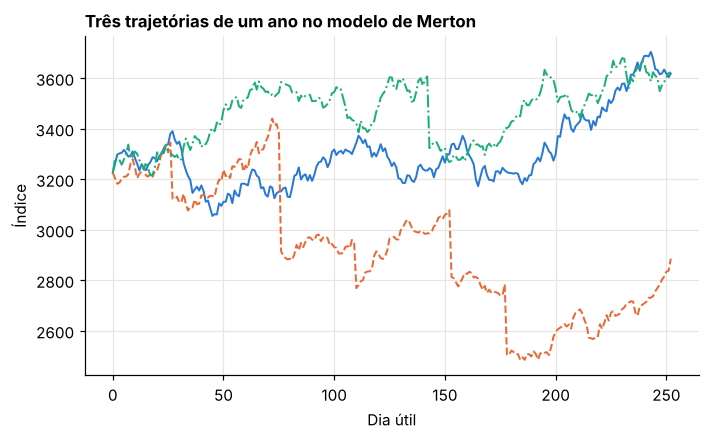

Compensação r_J: -0,254 | Volatilidade total equivalente: 0,197


In [2]:
LIVRO = dict(sig=0.113, lam=3.559, mu=-0.075, delta=0.041)


def r_j(lam, mu, delta):
    return lam * (np.exp(mu + 0.5 * delta**2) - 1)


rng = np.random.default_rng(1001)
dias = 252
dt = 1 / dias
fig, ax = plt.subplots()
for cor, est in zip([AZUL, LARANJA, VERDE], ["-", "--", "-."]):
    n = rng.poisson(LIVRO["lam"] * dt, dias)
    J = n * LIVRO["mu"] + np.sqrt(n) * LIVRO["delta"] * rng.standard_normal(dias)
    x = (R - r_j(**{k: LIVRO[k] for k in ("lam", "mu", "delta")}) - 0.5 * LIVRO["sig"] ** 2) * dt + LIVRO["sig"] * np.sqrt(dt) * rng.standard_normal(dias) + J
    ax.plot(np.arange(dias + 1), S0 * np.exp(np.r_[0.0, np.cumsum(x)]), color=cor, ls=est, lw=1.3)
ax.set_title("Três trajetórias de um ano no modelo de Merton")
ax.set_xlabel("Dia útil")
ax.set_ylabel("Índice")
plt.show()

print("Compensação r_J:", f3(r_j(LIVRO["lam"], LIVRO["mu"], LIVRO["delta"])), "| Volatilidade total equivalente:", f3(float(np.sqrt(LIVRO["sig"] ** 2 + LIVRO["lam"] * (LIVRO["mu"] ** 2 + LIVRO["delta"] ** 2)))))

---
## 2. Três formas de precificar

**Livro: §8.3**

### 2.1 A série de Poisson, deduzida

**Passo 1: condicionar no número de saltos.** Se $N_T = n$, o log-retorno é a soma de uma normal (difusão) com $n$ normais (saltos), logo é normal:

$$\ln\frac{S_T}{S_0}\,\Big|\,N_T = n \;\sim\; N\Big((r - r_J - \tfrac12\sigma^2)T + n\mu_J,\ \ \sigma^2T + n\delta^2\Big).$$

**Passo 2: reescrever como um BSM.** Procuramos $(r_n, \sigma_n)$ tais que essa normal seja a de um BSM. A variância dá $\sigma_n^2 = \sigma^2 + n\delta^2/T$. Para a média, exigimos $(r_n - \tfrac12\sigma_n^2)T = (r - r_J - \tfrac12\sigma^2)T + n\mu_J$. Resolvendo:

$$r_n = r - r_J + \frac{n(\mu_J + \tfrac12\delta^2)}{T} = r - r_J + \frac{n\ln(1+\kappa)}{T}, \qquad \kappa = e^{\mu_J + \delta^2/2} - 1.$$

**Passo 3: o desconto.** O BSM com taxa $r_n$ desconta a $r_n$, mas o desconto correto é a $r$. Logo, condicionado a $n$:

$$\mathbb{E}\big[e^{-rT}(S_T - K)^+\mid n\big] = e^{(r_n - r)T}\,C^{BSM}(S_0, K, T, r_n, \sigma_n).$$

**Passo 4: tirar a média nos $n$.** O fator $e^{(r_n - r)T} = e^{-r_JT}(1+\kappa)^n$ se junta à probabilidade de Poisson:

$$e^{-\lambda T}\frac{(\lambda T)^n}{n!}\,e^{-\lambda\kappa T}(1+\kappa)^n = e^{-\lambda'T}\frac{(\lambda'T)^n}{n!}, \qquad \lambda' = \lambda(1+\kappa).$$

Resulta a fórmula de Merton:

$$\boxed{C_0 = \sum_{n=0}^{\infty}e^{-\lambda'T}\frac{(\lambda'T)^n}{n!}\,C^{BSM}(S_0, K, T, r_n, \sigma_n).}$$

É uma média de preços BSM, com pesos de Poisson sob uma intensidade ajustada. Foi a fórmula usada como caixa-preta no Módulo 1.

### 2.2 Lewis e FFT

A função característica de $\ln(S_T/S_0) - rT$ é a do Módulo 7, e as fórmulas de Lewis e Carr-Madan se aplicam diretamente.

### Laboratório 2.1 — Os três métodos e um diagnóstico

Usamos os parâmetros e o prazo do script de simulação do livro ($T = 0{,}22$) e os mesmos strikes da sua tabela de resultados.

In [3]:
def cf_merton(u, T, sig, lam, mu, delta):
    om = -0.5 * sig**2 - r_j(lam, mu, delta)
    return np.exp(T * (1j * u * om - 0.5 * sig**2 * u**2 + lam * (np.exp(1j * u * mu - 0.5 * u**2 * delta**2) - 1)))


def lewis(S, K, T, r, cf, U=300.0, n=3001):
    K = np.atleast_1d(np.asarray(K, float))
    k = np.log(S / K) + r * T
    z = np.linspace(0.0, U, n)
    h = np.exp(1j * z * k[:, None]) * cf(z - 0.5j)
    return S - np.sqrt(S * K) * np.exp(-0.5 * r * T) / np.pi * simpson(h.real / (z**2 + 0.25), x=z, axis=1)


def merton_serie(S, K, T, r, sig, lam, mu, delta, n_max=80):
    kap = np.exp(mu + 0.5 * delta**2) - 1
    lq = lam * (1 + kap)
    tot = 0.0
    for n in range(n_max):
        sn = np.sqrt(sig**2 + n * delta**2 / T)
        rn = r - r_j(lam, mu, delta) + n * np.log1p(kap) / T
        tot = tot + poisson.pmf(n, lq * T) * bsm(S, K, T, rn, sn)
    return tot


def cm_fft(S, T, r, cf, alpha=1.5, N=4096, eps=1 / 150, k_ref=0.0):
    """Grade de FFT com o log-strike ln(K/S) = k_ref exatamente no ponto N/2, como no script do livro."""
    eta = 2 * np.pi / (N * eps)
    b = 0.5 * N * eps - k_ref
    j = np.arange(N)
    v = eta * j
    w = v - (alpha + 1) * 1j
    psi = np.exp(-r * T) * np.exp(1j * w * r * T) * cf(w) / (alpha**2 + alpha - v**2 + 1j * (2 * alpha + 1) * v)
    peso = (3 + (-1.0) ** (j + 1) - (j == 0)) * eta / 3
    k = -b + eps * j
    return S * np.exp(k), S * np.exp(-alpha * k) / np.pi * np.fft.fft(np.exp(1j * b * v) * psi * peso).real


def lewis_quad(S, K, T, r, cf, U):
    """Como no script do livro: integração adaptativa de 0 a U."""
    k = np.log(S / K) + r * T
    f = lambda z: (np.exp(1j * z * k) * cf(z - 0.5j)).real / (z**2 + 0.25)
    return S - np.sqrt(S * K) * np.exp(-0.5 * r * T) / np.pi * quad(f, 0, U, limit=250)[0]


T_l = 0.22
cf_l = lambda u: cf_merton(u, T_l, **LIVRO)
Kl = np.arange(3000.0, 3601.0, 100.0)
serie = merton_serie(S0, Kl, T_l, R, **LIVRO)
lw = lewis(S0, Kl, T_l, R, cf_l, U=400.0, n=40001)
fft = np.array([cm_fft(S0, T_l, R, cf_l, k_ref=np.log(k / S0))[1][2048] for k in Kl])
q50 = np.array([lewis_quad(S0, k, T_l, R, cf_l, 50.0) for k in Kl])
livro_int = {3000: 269.749, 3100: 194.905, 3200: 130.761, 3300: 79.695, 3400: 43.104, 3500: 20.232, 3600: 8.104}
livro_fft = {3000: 269.733, 3100: 194.890, 3200: 130.785, 3300: 79.705, 3400: 43.076, 3500: 20.224, 3600: 8.132}
tm = pd.DataFrame({"Strike": Kl, "Série": serie, "Lewis (até 400)": lw, "FFT": fft, "Lewis até 50": q50, "Livro: Int": [livro_int[int(k)] for k in Kl], "Livro: FFT": [livro_fft[int(k)] for k in Kl]})
tabela(tm)

ok(np.max(np.abs(lw - serie)) < 1e-6, "Lewis com limite adequado coincide com a série")
ok(np.max(np.abs(q50 - tm["Livro: Int"])) < 1e-3, "integrar só até 50 reproduz exatamente os valores 'Int' do livro")
ok(np.max(np.abs(serie - tm["Livro: FFT"])) < 0.002 and np.max(np.abs(fft - serie)) < 0.002, "os valores FFT, do livro e daqui, é que estão corretos")

,Strike,Série,Lewis (até 400),FFT,Lewis até 50,Livro: Int,Livro: FFT
0,"3.000,000","269,733","269,733","269,733","269,749","269,749","269,733"
1,"3.100,000","194,890","194,890","194,890","194,905","194,905","194,890"
2,"3.200,000","130,785","130,785","130,785","130,761","130,761","130,785"
3,"3.300,000","79,705","79,705","79,705","79,695","79,695","79,705"
4,"3.400,000","43,075","43,075","43,075","43,104","43,104","43,076"
5,"3.500,000","20,224","20,224","20,224","20,232","20,232","20,224"
6,"3.600,000","8,132","8,132","8,132","8,104","8,104","8,132"


OK — Lewis com limite adequado coincide com a série
OK — integrar só até 50 reproduz exatamente os valores 'Int' do livro
OK — os valores FFT, do livro e daqui, é que estão corretos


**Diagnóstico.** O livro interpreta a coluna "Difference FFT/Int" como imprecisão da FFT. É o contrário: a FFT está certa, e a integração numérica do script para em $z = 50$. Com prazo curto e volatilidade baixa, o integrando ainda não decaiu nesse ponto (Módulo 7, Seção 4). Ter uma terceira fonte independente, a série, é o que permite saber qual dos dois está certo.

---
## 3. O mercado sintético

O livro calibra a calls do EURO STOXX 50 com strikes até 5% do spot, em três prazos (17, 80 e 171 dias). Geramos preços com os mesmos prazos e strikes a cada 25 pontos, a partir de um modelo de volatilidade estocástica com saltos (o modelo dos Módulos 2 e 7), acrescentando ruído do tamanho de meio spread.

In [4]:
def cf_bates(u, T, v0, kappa, theta, nu, rho, lam, mu, delta):
    comp = lam * (np.exp(mu + 0.5 * delta**2) - 1)
    salto = np.exp(lam * T * (np.exp(1j * u * mu - 0.5 * u**2 * delta**2) - 1))
    xi = kappa - rho * nu * 1j * u
    d = np.sqrt(xi**2 + nu**2 * (1j * u + u**2))
    g = (xi - d) / (xi + d)
    e = np.exp(-d * T)
    A = kappa * theta / nu**2 * ((xi - d) * T - 2 * np.log((1 - g * e) / (1 - g)))
    B = (xi - d) / nu**2 * (1 - e) / (1 - g * e)
    return np.exp(-1j * u * comp * T) * salto * np.exp(A + B * v0)


VERDADE = dict(v0=0.03, kappa=1.5, theta=0.05, nu=0.45, rho=-0.75, lam=0.4, mu=-0.10, delta=0.08)
PRAZOS = {"17 dias": 17 / 365, "80 dias": 80 / 365, "171 dias": 171 / 365}

rng = np.random.default_rng(1002)
linhas = []
for nome, T in PRAZOS.items():
    K = np.arange(np.ceil(0.95 * S0 / 25) * 25, 1.05 * S0, 25.0)
    preco = lewis(S0, K, T, R, lambda u: cf_bates(u, T, **VERDADE))
    ruido = rng.normal(0.0, np.maximum(0.25, 0.005 * preco))
    for k, p, e in zip(K, preco, ruido):
        linhas.append({"Prazo": nome, "T": T, "Strike": k, "Preço justo": p, "Cotação": p + e})
mercado = pd.DataFrame(linhas)
mercado["Vol. implícita"] = [vol_impl(l.Cotação, S0, l.Strike, l.T, R) for l in mercado.itertuples()]
print("Cotações:", len(mercado))
tabela(mercado.groupby("Prazo", sort=False).agg(Opções=("Strike", "size"), **{"Menor strike": ("Strike", "min"), "Maior strike": ("Strike", "max"), "Vol. implícita mínima": ("Vol. implícita", "min"), "Vol. implícita máxima": ("Vol. implícita", "max")}).reset_index())
ok(mercado["Vol. implícita"].notna().all(), "todas as cotações têm volatilidade implícita")

Cotações: 39


,Prazo,Opções,Menor strike,Maior strike,Vol. implícita mínima,Vol. implícita máxima
0,17 dias,13,"3.075,000","3.375,000","0,155","0,214"
1,80 dias,13,"3.075,000","3.375,000","0,166","0,206"
2,171 dias,13,"3.075,000","3.375,000","0,177","0,207"


OK — todas as cotações têm volatilidade implícita


---
## 4. Calibração

**Livro: §8.4**

### 4.1 O problema

Escolhemos os parâmetros que minimizam a distância entre modelo e mercado. O livro usa a raiz do erro quadrático médio em preço:

$$\min_{\sigma,\lambda,\mu_J,\delta}\ \sqrt{\frac1N\sum_{n=1}^N\Big(C_n^{*} - C_n^{M76}(\sigma,\lambda,\mu_J,\delta)\Big)^2}.$$

### 4.2 Por que é difícil

O problema é **mal posto**: a solução pode não ser única, nem depender de forma estável dos dados. Na prática, aparecem três sintomas:

1. **Mínimos locais.** Um otimizador local fica preso no primeiro vale.
2. **Vales planos.** Combinações diferentes de parâmetros dão quase o mesmo erro. Em Merton, muitos saltos pequenos se parecem com volatilidade a mais.
3. **Restrições.** $\sigma, \delta > 0$ e $\lambda \ge 0$. O livro usa penalidades; aqui usamos limites diretos no otimizador.

### 4.3 A estratégia em duas etapas

**Etapa global:** avaliar o erro numa grade grosseira de parâmetros (força bruta) e escolher o melhor ponto.
**Etapa local:** partir dele com um otimizador de mínimos quadrados.

### Laboratório 4.1 — Calibração aos três prazos

In [5]:
def erros(x, dados):
    sig, lam, mu, delta = x
    saida = []
    for T, g in dados.groupby("T"):
        saida.append(lewis(S0, g["Strike"].values, T, R, lambda u: cf_merton(u, T, sig, lam, mu, delta)) - g["Cotação"].values)
    return np.concatenate(saida)


def rmse(x, dados):
    if x[0] <= 0 or x[1] < 0 or x[3] <= 0:
        return 1e6
    return float(np.sqrt(np.mean(erros(x, dados) ** 2)))


LIM = ([0.01, 0.0, -0.6, 0.001], [0.6, 5.0, 0.2, 0.5])
GRADE = ((0.075, 0.201, 0.025), (0.10, 0.401, 0.10), (-0.5, 0.01, 0.10), (0.10, 0.301, 0.10))


def calibrar(dados):
    t0 = perf_counter()
    x0 = brute(lambda x: rmse(x, dados), GRADE, finish=None)
    res = least_squares(lambda x: erros(x, dados), x0, bounds=LIM)
    return x0, res.x, perf_counter() - t0


x0_todos, x_todos, t_todos = calibrar(mercado)
tabela(pd.DataFrame({"Parâmetro": ["σ", "λ", "μ_J", "δ"], "Melhor ponto da grade": x0_todos, "Após otimização local": x_todos}))
print("Tempo:", f3(t_todos), "s | RMSE na grade:", f3(rmse(x0_todos, mercado)), "| RMSE final:", f3(rmse(x_todos, mercado)))

por_prazo = []
for nome, T in PRAZOS.items():
    g = mercado[mercado["T"] == T]
    por_prazo.append({"Prazo": nome, "RMSE em preço": rmse(x_todos, g)})
tabela(pd.DataFrame(por_prazo))
ok(rmse(x_todos, mercado) < rmse(x0_todos, mercado), "a etapa local melhora o ponto da grade")
ok(min(p["RMSE em preço"] for p in por_prazo) > 1.0, "com quatro parâmetros, Merton não ajusta bem nenhum dos três prazos ao mesmo tempo")

,Parâmetro,Melhor ponto da grade,Após otimização local
0,σ,"0,150","0,138"
1,λ,"0,200","0,698"
2,μ_J,"-0,400","-0,167"
3,δ,"0,200","0,081"


Tempo: 2,625 s | RMSE na grade: 3,622 | RMSE final: 2,939


,Prazo,RMSE em preço
0,17 dias,"3,239"
1,80 dias,"2,023"
2,171 dias,"3,366"


OK — a etapa local melhora o ponto da grade
OK — com quatro parâmetros, Merton não ajusta bem nenhum dos três prazos ao mesmo tempo


### Laboratório 4.2 — Calibração só ao prazo mais curto

O livro observa que, restrito ao prazo mais curto, Merton ajusta muito bem. É o papel que os saltos terão no modelo geral: cuidar dos prazos curtos, enquanto a volatilidade estocástica cuida dos longos.

In [6]:
curto = mercado[mercado["Prazo"] == "17 dias"]
x0_curto, x_curto, t_curto = calibrar(curto)
tabela(pd.DataFrame({"Parâmetro": ["σ", "λ", "μ_J", "δ"], "Três prazos": x_todos, "Só 17 dias": x_curto, "Livro (só 17 dias)": [0.113, 3.559, -0.075, 0.041]}))

linhas = []
for nome, T in PRAZOS.items():
    g = mercado[mercado["T"] == T]
    linhas.append({"Prazo": nome, "RMSE: calibrado aos três": rmse(x_todos, g), "RMSE: calibrado a 17 dias": rmse(x_curto, g)})
fora = pd.DataFrame(linhas).set_index("Prazo")
tabela(fora.reset_index())
ok(fora.loc["17 dias", "RMSE: calibrado a 17 dias"] < 0.5, "no prazo curto, o ajuste fica dentro do tamanho do spread")
ok(fora.loc["171 dias", "RMSE: calibrado a 17 dias"] > 2 * fora.loc["171 dias", "RMSE: calibrado aos três"], "mas extrapola muito mal para prazos mais longos")

,Parâmetro,Três prazos,Só 17 dias,Livro (só 17 dias)
0,σ,"0,138","0,131","0,113"
1,λ,"0,698","5,000","3,559"
2,μ_J,"-0,167","-0,061","-0,075"
3,δ,"0,081","0,001","0,041"


,Prazo,RMSE: calibrado aos três,RMSE: calibrado a 17 dias
0,17 dias,"3,239","0,496"
1,80 dias,"2,023","5,048"
2,171 dias,"3,366","8,126"


OK — no prazo curto, o ajuste fica dentro do tamanho do spread
OK — mas extrapola muito mal para prazos mais longos


**Leitura dos parâmetros.** Repare na calibração ao prazo curto: muitos saltos e muito pequenos, como no livro ($\lambda = 3{,}559$, $\delta = 0{,}041$). Aqui o resultado é ainda mais extremo: $\lambda$ para no limite superior imposto (5) e $\delta$ praticamente zera, ou seja, saltos quase determinísticos de tamanho $\mu_J$. Com um único prazo, a calibração encontra uma combinação que imita a forma do sorriso, mas que não representa saltos raros e grandes, como os do modelo verdadeiro ($\lambda = 0{,}4$, $\mu_J = -0{,}10$). É a mesma identificabilidade fraca que vimos no Módulo 1.

### Laboratório 4.3 — A paisagem do erro

Fixamos $\sigma$ e $\delta$ no ótimo do prazo curto e desenhamos o RMSE em função de $\lambda$ e $\mu_J$.

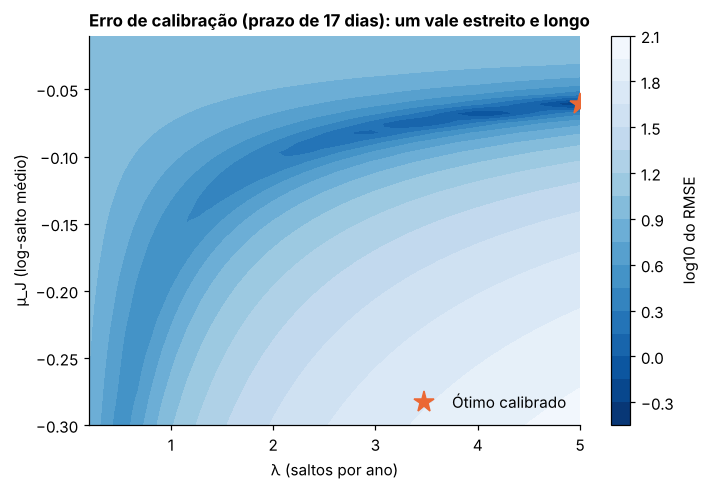

Fração da grade com RMSE até o dobro do mínimo: 0,007 | Faixa de λ nessa região: 3,320 a 5,000
OK — há uma faixa larga de λ com erro próximo do mínimo


In [7]:
lam_g = np.linspace(0.2, 5.0, 41)
mu_g = np.linspace(-0.30, -0.01, 41)
Zg = np.array([[rmse([x_curto[0], l, m, x_curto[3]], curto) for l in lam_g] for m in mu_g])

fig, ax = plt.subplots(figsize=(7.2, 4.6))
cs = ax.contourf(lam_g, mu_g, np.log10(Zg), levels=20, cmap="Blues_r")
fig.colorbar(cs, ax=ax, label="log10 do RMSE")
ax.plot(x_curto[1], x_curto[2], marker="*", markersize=14, color=LARANJA, ls="none", label="Ótimo calibrado")
ax.set_title("Erro de calibração (prazo de 17 dias): um vale estreito e longo")
ax.set_xlabel("λ (saltos por ano)")
ax.set_ylabel("μ_J (log-salto médio)")
ax.legend(loc="lower right")
plt.show()

vale = Zg < 2 * Zg.min()
print("Fração da grade com RMSE até o dobro do mínimo:", f3(float(vale.mean())), "| Faixa de λ nessa região:", f3(float(lam_g[vale.any(axis=0)].min())), "a", f3(float(lam_g[vale.any(axis=0)].max())))
ok(np.ptp(lam_g[vale.any(axis=0)]) > 1.0, "há uma faixa larga de λ com erro próximo do mínimo")

O vale acompanha uma curva em que o produto $\lambda\mu_J$, aproximadamente o drift dos saltos, fica estável. Com os dados de um prazo, o mercado informa bem essa combinação, mas mal cada parâmetro separadamente.

### Laboratório 4.4 — O ajuste em volatilidade implícita

Comparar em preço esconde problemas nos strikes altos, em que os preços são pequenos. A volatilidade implícita põe todos na mesma escala.

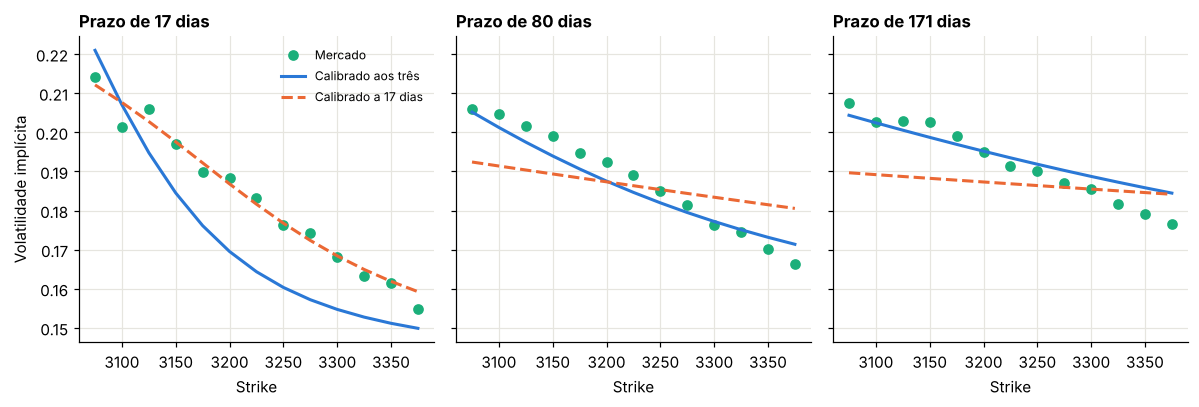

In [8]:
fig, eixos = plt.subplots(1, 3, figsize=(11, 3.8), sharey=True)
for ax, (nome, T) in zip(eixos, PRAZOS.items()):
    g = mercado[mercado["T"] == T]
    ax.plot(g["Strike"], g["Vol. implícita"], "o", color=VERDE, markersize=6, label="Mercado")
    for x, cor, est, rot in [(x_todos, AZUL, "-", "Calibrado aos três"), (x_curto, LARANJA, "--", "Calibrado a 17 dias")]:
        p = lewis(S0, g["Strike"].values, T, R, lambda u: cf_merton(u, T, *x))
        ax.plot(g["Strike"], [vol_impl(pp, S0, k, T, R) for pp, k in zip(p, g["Strike"])], color=cor, ls=est, label=rot)
    ax.set_title(f"Prazo de {nome}")
    ax.set_xlabel("Strike")
eixos[0].set_ylabel("Volatilidade implícita")
eixos[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

---
## 5. Simulação

**Livro: §8.5**

### 5.1 Três esquemas

O livro apresenta duas discretizações. Na primeira, tudo é somado:

$$S_t = S_{t-\Delta t}\Big[1 + (r - r_J)\Delta t + \sigma\sqrt{\Delta t}\,z^1_t + \big(e^{\mu_J + \delta z^2_t} - 1\big)y_t\Big].$$

Na segunda, a difusão vira exponencial, mas o salto continua somado:

$$S_t = S_{t-\Delta t}\Big[e^{(r - r_J - \sigma^2/2)\Delta t + \sigma\sqrt{\Delta t}\,z^1_t} + \big(e^{\mu_J + \delta z^2_t} - 1\big)y_t\Big].$$

Nas duas, se houver $y_t = 2$ saltos no mesmo passo, o tamanho aplicado é **o dobro de um único salto**, em vez da soma de dois saltos independentes, e o salto é somado à difusão, em vez de multiplicado. A média fica correta, mas a distribuição não.

O esquema **exato** usa o log-preço, em que tudo soma de verdade:

$$\ln S_t = \ln S_{t-\Delta t} + (r - r_J - \tfrac12\sigma^2)\Delta t + \sigma\sqrt{\Delta t}\,z^1_t + y_t\mu_J + \sqrt{y_t}\,\delta\,z^2_t.$$

A soma de $y_t$ normais independentes $N(\mu_J,\delta^2)$ é $N(y_t\mu_J, y_t\delta^2)$, daí o $\sqrt{y_t}$. Para uma opção europeia, nem é preciso discretizar: um único passo de tamanho $T$ é exato.

### Laboratório 5.1 — Há viés?

O livro mostra uma única simulação, com diferenças positivas e decrescentes em relação à fórmula (de +0,754 a +0,057). Com uma só semente, não dá para distinguir erro de amostragem de viés. Para medir o viés com precisão, usamos uma técnica do Módulo 12, as **variáveis comuns**: os três esquemas recebem exatamente os mesmos números aleatórios. O ruído quase se cancela na diferença, e o que sobra é o efeito do esquema. Repetimos 20 vezes, com 200 mil trajetórias e 50 passos, como no livro.

In [9]:
def tres_esquemas(rng, T, M, I, sig, lam, mu, delta):
    """Simula os três esquemas com os MESMOS números aleatórios (variáveis comuns)."""
    dt = T / M
    rj = r_j(lam, mu, delta)
    Sa, Sb, x = np.full(I, S0), np.full(I, S0), np.zeros(I)
    for _ in range(M):
        z1, z2, y = rng.standard_normal(I), rng.standard_normal(I), rng.poisson(lam * dt, I)
        salto_livro = (np.exp(mu + delta * z2) - 1) * y
        Sa = Sa * (1 + (R - rj) * dt + sig * np.sqrt(dt) * z1 + salto_livro)
        Sb = Sb * (np.exp((R - rj - 0.5 * sig**2) * dt + sig * np.sqrt(dt) * z1) + salto_livro)
        x += (R - rj - 0.5 * sig**2) * dt + sig * np.sqrt(dt) * z1 + y * mu + np.sqrt(y) * delta * z2
    return {"Livro, aditivo": Sa, "Livro, log da difusão": Sb, "Exato": S0 * np.exp(x)}


Kt = np.array([3000.0, 3200.0, 3400.0, 3600.0])
refe = merton_serie(S0, Kt, T_l, R, **LIVRO)
rng = np.random.default_rng(1003)
acum = {nome: [] for nome in ["Livro, aditivo", "Livro, log da difusão", "Exato"]}
for _ in range(20):
    S = tres_esquemas(rng, T_l, 50, 200_000, **LIVRO)
    pay = {n: np.exp(-R * T_l) * np.maximum(v[:, None] - Kt, 0.0) for n, v in S.items()}
    for n in acum:
        acum[n].append(pay[n].mean(axis=0) - (refe if n == "Exato" else pay["Exato"].mean(axis=0)))

linhas = []
for nome, rot in [("Exato", "Exato − fórmula"), ("Livro, aditivo", "Livro aditivo − exato"), ("Livro, log da difusão", "Livro log − exato")]:
    d = np.array(acum[nome])
    for k, mm, ee in zip(Kt, d.mean(axis=0), d.std(axis=0, ddof=1) / np.sqrt(20)):
        linhas.append({"Comparação": rot, "Strike": k, "Diferença média": mm, "Erro-padrão": ee, "Em erros-padrão": mm / ee})
vies = pd.DataFrame(linhas)
tabela(vies)
ok((vies.query("Comparação == 'Exato − fórmula'")["Em erros-padrão"].abs() < 3.5).all(), "o esquema exato não tem viés detectável")
ok((vies.query("Comparação == 'Livro log − exato'")["Em erros-padrão"] > 4).all(), "com as mesmas trajetórias, o viés do esquema do livro aparece com clareza")

,Comparação,Strike,Diferença média,Erro-padrão,Em erros-padrão
0,Exato − fórmula,"3.000,000","0,044","0,117","0,381"
1,Exato − fórmula,"3.200,000","0,045","0,082","0,545"
2,Exato − fórmula,"3.400,000","0,026","0,044","0,599"
3,Exato − fórmula,"3.600,000","0,011","0,016","0,657"
4,Livro aditivo − exato,"3.000,000","0,130","0,002","58,653"
5,Livro aditivo − exato,"3.200,000","0,032","0,002","19,135"
6,Livro aditivo − exato,"3.400,000","-0,045","0,001","-40,860"
7,Livro aditivo − exato,"3.600,000","-0,041","0,001","-68,273"
8,Livro log − exato,"3.000,000","0,234","0,002","106,062"
9,Livro log − exato,"3.200,000","0,132","0,002","82,714"


OK — o esquema exato não tem viés detectável
OK — com as mesmas trajetórias, o viés do esquema do livro aparece com clareza


**Leitura.** O viés do esquema do livro é pequeno, mas real, positivo e decrescente com o strike, como as diferenças que ele relata. Contra a fórmula, sozinho, ele mal se distingue do ruído de 200 mil trajetórias; com variáveis comuns, fica evidente. O restante das diferenças do livro é ruído de uma única semente, com o mesmo sinal em todos os strikes porque as mesmas trajetórias servem a todos eles.

---
## 6. Usando o modelo: um exótico e o risco de modelo

O objetivo de calibrar é precificar o que o mercado não cota. Tomamos uma **down-and-in put** de 171 dias: uma put com strike no dinheiro que só passa a existir se o índice tocar 85% do valor atual, com monitoramento diário.

Comparamos quatro precificações:

1. **Verdade:** o modelo que gerou o mercado.
2. **Merton calibrado aos três prazos.**
3. **Merton calibrado a 17 dias.**
4. **BSM** com a volatilidade implícita ATM de 171 dias.

### Laboratório 6.1 — Quanto custa errar o modelo

In [10]:
T_x, H = 171 / 365, 0.85 * S0
M_x, I_x = 117, 100_000


def dip(S):
    tocou = S.min(axis=0) <= H
    return np.exp(-R * T_x) * np.maximum(S0 - S[-1], 0.0) * tocou


def caminhos_merton(rng, sig, lam, mu, delta):
    dt = T_x / M_x
    y = rng.poisson(lam * dt, (M_x, I_x))
    x = (R - r_j(lam, mu, delta) - 0.5 * sig**2) * dt + sig * np.sqrt(dt) * rng.standard_normal((M_x, I_x)) + y * mu + np.sqrt(y) * delta * rng.standard_normal((M_x, I_x))
    return S0 * np.exp(np.vstack([np.zeros(I_x), np.cumsum(x, axis=0)]))


def caminhos_bates(rng, v0, kappa, theta, nu, rho, lam, mu, delta):
    dt = T_x / M_x
    v = np.full(I_x, v0)
    x = np.zeros(I_x)
    S = [np.full(I_x, S0)]
    comp = lam * (np.exp(mu + 0.5 * delta**2) - 1)
    for _ in range(M_x):
        z1 = rng.standard_normal(I_x)
        z2 = rho * z1 + np.sqrt(1 - rho**2) * rng.standard_normal(I_x)
        vp = np.maximum(v, 0.0)
        y = rng.poisson(lam * dt, I_x)
        x += (R - comp - 0.5 * vp) * dt + np.sqrt(vp * dt) * z1 + y * mu + np.sqrt(y) * delta * rng.standard_normal(I_x)
        v += kappa * (theta - vp) * dt + nu * np.sqrt(vp * dt) * z2
        S.append(S0 * np.exp(x))
    return np.array(S)


g171 = mercado[mercado["Prazo"] == "171 dias"]
vol_atm = float(np.interp(S0, g171["Strike"], g171["Vol. implícita"]))
rng = np.random.default_rng(1004)
modelos = {
    "Verdade (vol. estoc. + saltos)": caminhos_bates(rng, **VERDADE),
    "Merton, três prazos": caminhos_merton(rng, *x_todos),
    "Merton, 17 dias": caminhos_merton(rng, *x_curto),
    "BSM com vol. ATM": caminhos_merton(rng, vol_atm, 0.0, 0.0, 0.01),
}
linhas = []
for nome, S in modelos.items():
    a = dip(S)
    eur = np.exp(-R * T_x) * np.maximum(S0 - S[-1], 0.0)
    linhas.append({"Modelo": nome, "Put europeia ATM": float(eur.mean()), "Down-and-in put": float(a.mean()), "Erro-padrão": float(a.std(ddof=1) / np.sqrt(I_x)), "P(tocar a barreira)": float((S.min(axis=0) <= H).mean())})
ex = pd.DataFrame(linhas).set_index("Modelo")
tabela(ex.reset_index())

v = ex["Down-and-in put"]
ok(abs(ex["Put europeia ATM"].iloc[1] - ex["Put europeia ATM"].iloc[0]) < 0.05 * ex["Put europeia ATM"].iloc[0], "o Merton calibrado aos três prazos acerta a put europeia ATM com erro menor que 5%")
ok(abs(v.iloc[3] - v.iloc[0]) > abs(v.iloc[1] - v.iloc[0]), "o BSM erra mais o exótico do que o Merton calibrado aos três prazos")
ok(v.max() / v.min() > 1.2, "os quatro modelos discordam em mais de 20% no exótico")

,Modelo,Put europeia ATM,Down-and-in put,Erro-padrão,P(tocar a barreira)
0,Verdade (vol. estoc. + saltos),"165,424","132,411","0,909","0,247"
1,"Merton, três prazos","165,730","119,214","0,872","0,191"
2,"Merton, 17 dias","161,353","104,713","0,733","0,200"
3,BSM com vol. ATM,"164,636","104,990","0,715","0,210"


OK — o Merton calibrado aos três prazos acerta a put europeia ATM com erro menor que 5%
OK — o BSM erra mais o exótico do que o Merton calibrado aos três prazos
OK — os quatro modelos discordam em mais de 20% no exótico


**Leitura.** Todos os modelos foram calibrados aos mesmos dados e concordam razoavelmente na put europeia. No exótico, a dispersão é bem maior: o valor depende da probabilidade de tocar a barreira, que é uma propriedade da **dinâmica**, e não da distribuição terminal. Medir essa dispersão é uma forma direta de quantificar o risco de modelo, e é o que motiva o modelo geral dos próximos módulos.

---
## 7. Síntese

- Merton é BSM mais saltos lognormais compensados.
- A fórmula fechada é uma mistura de preços BSM com pesos de Poisson.
- Três métodos independentes permitem diagnosticar erros numéricos; um deles, sozinho, não.
- Calibrar é mal posto: há vales planos, e o mesmo ajuste é compatível com parâmetros muito diferentes.
- Merton ajusta bem um prazo, mas não vários ao mesmo tempo.
- Somar o salto à difusão, como no livro, introduz viés; o esquema em log é exato.
- Os modelos calibrados concordam nos vanilla e discordam nos exóticos: isso é risco de modelo.

## 8. Notas sobre o livro neste capítulo

| Local | Comentário |
|---|---|
| §8.2 | a lei $\ln(1+J) \sim N(\ln(1+\mu_J) - \delta^2/2, \delta^2)$ não é a usada em $r_J$, em (8.2) e nos scripts, que correspondem a $\ln(1+J) \sim N(\mu_J, \delta^2)$ |
| §8.5, saída do script | os valores "Int" usam integração até $z = 50$, curta demais para $T = 0{,}22$; são os valores FFT que estão corretos |
| Equações (8.5) e (8.6) | o salto é somado, e $y$ saltos no mesmo passo usam um único tamanho multiplicado por $y$; o esquema tem viés |
| §8.5, saída do script | a diferença entre simulação e fórmula combina esse viés com ruído de uma única semente |
| Script 8.7.5 | comenta "T = 0.22 # shortest maturity", mas o prazo mais curto é de 17 dias (0,047 ano) |

## 9. Exercícios

**Exercício 1.** Mostre que, com $\lambda = 0$, a série de Merton se reduz ao BSM.

<details><summary>Solução</summary>

Com $\lambda = 0$, $\lambda' = 0$: só o termo $n = 0$ tem peso, e ele vale 1. Como $r_J = 0$, $r_0 = r$ e $\sigma_0 = \sigma$.
</details>

**Exercício 2.** Calcule a variância total por unidade de tempo dos parâmetros do livro e compare com $\sigma$.

<details><summary>Solução</summary>

$\sigma^2 + \lambda(\mu_J^2 + \delta^2) = 0{,}113^2 + 3{,}559(0{,}075^2 + 0{,}041^2) = 0{,}039$. A volatilidade total é $0{,}197$, bem acima de $\sigma = 0{,}113$: a maior parte da variância vem dos saltos.
</details>

**Exercício 3.** Por que calibrar em volatilidade implícita, em vez de preço, muda o peso relativo das opções fora do dinheiro?

<details><summary>Solução</summary>

Um erro de preço $\Delta C$ equivale a um erro de volatilidade $\Delta C/\text{vega}$. Como o vega é pequeno longe do dinheiro, o mesmo erro em preço vira um erro grande em volatilidade, e essas opções passam a pesar mais. O Módulo 13 discute as alternativas.
</details>

**Exercício 4.** Recalibre o Merton aos três prazos, mas só com os strikes acima do spot. O que acontece com $\mu_J$? Por quê?

<details><summary>Solução</summary>

As calls fora do dinheiro trazem pouca informação sobre a cauda esquerda, onde atuam os saltos negativos. $\mu_J$ fica mal determinado, e pode até mudar de sinal. A escolha dos dados de calibração é parte do modelo.
</details>

In [11]:
print(f"Módulo 10 concluído: {_checks['n']} verificações aprovadas.")

Módulo 10 concluído: 14 verificações aprovadas.
